# 08 · Putting it all together: simulation, full backtest & live predictions

Every component from notebooks 04–07 is combined by **simulating each player's match 10,000 times**:

```
minutes class (0 / 1–59 / 60+)            ← minutes model (04), capped by FPL injury flags live
team goals for / against                    ← team strength (05), Poisson
goals while he's on the pitch               ← Binomial(team goals, minutes/90)
his goals, then assists                     ← each on-pitch team goal is his with prob = his share (06)
clean sheet, goals conceded                 ← on-pitch goals against; CS needs 60+ minutes
defensive contribution, saves, cards        ← component models (07), at the simulated minutes
bonus                                       ← E[bonus | this draw's events] (07), drawn 0–3
→ score every draw with the 2026-27 rules; sum a player's draws across a double gameweek
```

So each player gets **expected points**, **P(return 6+)**, **P(haul 10+)**, a **range** (10th–90th percentile) and a
**breakdown** by component. Because events are simulated *together*, they're consistent: a player can't outscore his
team, a clean sheet requires 60 minutes, and a brace comes with bonus.

Code: [`fpl_engine/models/simulate.py`](../fpl_engine/models/simulate.py) · [`fpl_engine/models/direct.py`](../fpl_engine/models/direct.py) ·
[`fpl_engine/live.py`](../fpl_engine/live.py)

In [1]:
import sys, warnings, pathlib; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db, backtest, live
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 220, 'display.max_columns', 30)
BT = pathlib.Path('../data/backtests')
# The full backtest takes ~10 minutes, so it's run once by script and loaded here:
#   preds = backtest.run(frame, all_baselines() + [DirectLGBM(), ComponentModel(rules, n_sims=10_000)])
preds = pd.read_parquet(BT / 'full_v1.parquet')
gw = backtest.to_gameweeks(preds)
print(f"{gw.gw_key.nunique()} gameweeks (2024-25 → 2026-27), {gw.model.nunique()} models, retrained every 5 gameweeks")

87 gameweeks (2024-25 → 2026-27), 7 models, retrained every 5 gameweeks


## 1 · The headline: rotation-relevant players, per player-gameweek

Your primary metric is **top-20 picks' actual points** (each gameweek, take the model's 20 highest predictions among
rotation-relevant players; how many points did they actually score?), with MAE and calibration as guard-rails.

In [2]:
head = backtest.metrics(gw).loc['rotation-relevant'].drop(index='zero').sort_values('top20 picks: actual pts', ascending=False)
head.round(3)

,rows,MAE,RMSE,bias,rank corr / GW,top20 picks: actual pts,top20 hindsight max
model,,,,,,,
component_sim,26461,2.000,2.830,-0.001,0.455,4.957,10.952
direct_lgbm,26461,2.023,2.849,0.025,0.443,4.800,10.952
simple_linear,26461,2.035,2.867,-0.025,0.433,4.770,10.952
season_avg,26461,2.129,3.026,-0.003,0.344,4.378,10.952
last5_avg,26461,2.234,3.102,0.196,0.319,4.195,10.952
fpl_form,26461,2.328,3.223,0.344,0.287,3.916,10.952


In [3]:
rr = gw[gw.rotation_relevant]
top = rr.sort_values('xpts', ascending=False).groupby(['model', 'gw_key']).head(20).groupby(['model', 'gw_key']).y_points.mean().unstack(0)
rows = []
for other in ['direct_lgbm', 'simple_linear', 'season_avg', 'fpl_form']:
    d = top.component_sim - top[other]
    rows.append({'compared with': other, 'extra pts per pick per GW': d.mean(), 'standard error': d.std() / np.sqrt(len(d)),
                 'GWs where component wins': (d > 0).mean(), 'over a 38-GW season, 11 picks': d.mean() * 11 * 38})
pd.DataFrame(rows).set_index('compared with').round(3)

,extra pts per pick per GW,standard error,GWs where component wins,"over a 38-GW season, 11 picks"
compared with,,,,
direct_lgbm,0.157,0.086,0.586,65.583
simple_linear,0.187,0.091,0.586,78.315
season_avg,0.589,0.103,0.701,245.995
fpl_form,1.045,0.107,0.851,436.978


How to read this:
- The **component model is best on every measure**: top-20 picks, MAE, RMSE, rank correlation, and its bias is ≈ 0.
- Against the **direct LightGBM** benchmark the edge is **~0.16 points per pick per gameweek**, about 1.8 standard
  errors: suggestive, not yet conclusive. Against the simple linear model it's ~2 standard errors; against season
  averages and FPL form it's decisive.
- Football is very noisy; even the hindsight-perfect top 20 averages ~11 points while good models get ~5. The gaps between
  good models are small per pick but add up over a season of 11 players.

In [4]:
by_season = rr.assign(s=rr.season).sort_values('xpts', ascending=False).groupby(['model', 'gw_key']).head(20) \
    .groupby(['s', 'model']).y_points.mean().unstack()[['component_sim', 'direct_lgbm', 'simple_linear', 'season_avg']]
by_season.round(2)

model,component_sim,direct_lgbm,simple_linear,season_avg
s,,,,
2024-25,5.21,5.17,5.07,4.60
2025-26,4.71,4.47,4.50,4.28
2026-27,4.93,4.67,4.66,3.90


## 2 · Are the probabilities trustworthy?

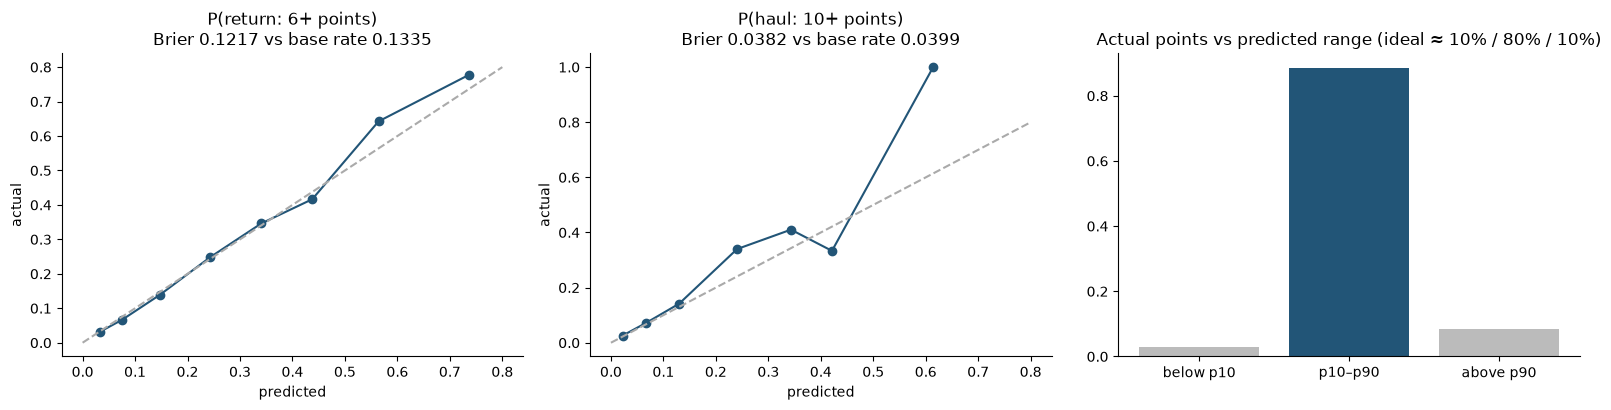

In [5]:
c = rr[rr.model == 'component_sim']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, thr, title) in zip(axes[:2], [('p_return', 6, 'P(return: 6+ points)'), ('p_haul', 10, 'P(haul: 10+ points)')]):
    y = (c.y_points >= thr).astype(float)
    cal = pd.DataFrame({'p': c[col], 'y': y}).groupby(pd.cut(c[col], [0, .05, .1, .2, .3, .4, .5, .7, 1]), observed=True) \
        .agg(pred=('p', 'mean'), act=('y', 'mean'), n=('y', 'size'))
    ax.plot(cal.pred, cal.act, marker='o', color='#257'); ax.plot([0, .8], [0, .8], '--', color='#aaa')
    ax.set_title(f"{title}\nBrier {((c[col] - y) ** 2).mean():.4f} vs base rate {((y.mean() - y) ** 2).mean():.4f}")
    ax.set_xlabel('predicted'); ax.set_ylabel('actual')
inside = ((c.y_points >= c.p10) & (c.y_points <= c.p90)).mean()
axes[2].bar(['below p10', 'p10–p90', 'above p90'],
            [(c.y_points < c.p10).mean(), inside, (c.y_points > c.p90).mean()], color=['#bbb', '#257', '#bbb'])
axes[2].set_title(f'Actual points vs predicted range (ideal ≈ 10% / 80% / 10%)'); plt.tight_layout(); plt.show()

- **P(return)** tracks the diagonal closely and beats the base rate clearly.
- **P(haul)** is a little low (≈3.7% predicted vs 4.2% actual): the hardest thing to predict, since a haul needs several
  things to go right at once. One to improve (e.g. bonus and goals are slightly more correlated in reality than
  in the simulation).
- The 10th–90th percentile range contains the actual score ~89% of the time (a bit wide, partly because points are
  whole numbers, so many scores sit exactly on a percentile).

## 3 · Where does it win?

In [6]:
cols = ['component_sim', 'direct_lgbm', 'simple_linear']
gw['price_bracket'] = pd.cut(gw.price, [0, 5, 6.5, 8.5, 20], labels=['≤5.0', '5.1–6.5', '6.6–8.5', '8.6+'])
print('MAE by position'); print(backtest.by_group(gw, 'position')[cols].round(3).to_string())
print('\nMAE by price'); print(backtest.by_group(gw, 'price_bracket')[cols].round(3).to_string())

MAE by position
model     component_sim  direct_lgbm  simple_linear
position                                           
DEF               2.130        2.134          2.162
FWD               2.155        2.190          2.173
GKP               2.071        2.121          2.116
MID               1.865        1.894          1.904

MAE by price
model          component_sim  direct_lgbm  simple_linear
price_bracket                                           
≤5.0                   1.821        1.809          1.830
5.1–6.5                2.026        2.061          2.066
6.6–8.5                2.588        2.705          2.685
8.6+                   3.402        3.665          3.692


## 4 · Re-test: team-specific home advantage (notebook 05 follow-up)

You chose to leave it off and re-test on players' points once the full model existed. Same backtest, with each team's own
(heavily shrunk) home bonus:

In [7]:
th_path = BT / 'full_v1_team_home.parquet'
if th_path.exists():
    th = backtest.to_gameweeks(pd.concat([preds[preds.model == 'component_sim'], pd.read_parquet(th_path)]))
    m2 = backtest.metrics(th).loc['rotation-relevant']
    t2 = th[th.rotation_relevant].sort_values('xpts', ascending=False).groupby(['model', 'gw_key']).head(20) \
        .groupby(['model', 'gw_key']).y_points.mean().unstack(0)
    d = t2.component_sim_team_home - t2.component_sim
    display(m2[['MAE', 'rank corr / GW', 'top20 picks: actual pts']].round(3))
    print(f"team-specific minus league-wide: {d.mean():+.3f} pts per pick per GW (SE {d.std() / np.sqrt(len(d)):.3f})")
else:
    print('team-home backtest not run yet')

,MAE,rank corr / GW,top20 picks: actual pts
model,,,
component_sim,2.0,0.455,4.957
component_sim_team_home,2.0,0.455,4.942


team-specific minus league-wide: -0.015 pts per pick per GW (SE 0.023)


## 5 · Live: gameweek predictions

`live.predict_gameweek` builds pre-deadline rows for every current player's next fixture(s), fits the components on all
history, then applies the two **live overlays** you approved:
- **Availability**: FPL's injury/suspension flags cap P(plays) (e.g. "75% chance" → at most 75%; injured → 0).
- **Penalty takers**: FPL's first-choice taker gets his team's expected penalty xG; a player who has been taking
  penalties but no longer is first choice loses it.

Running it from the notebook doesn't store anything; `python -m fpl_engine predict` (and the daily job) stores each run
in `predictions.*`, append-only.

In [8]:
with db.connect() as conn:
    out, det = live.predict_gameweek(conn, write=False, details=True)
    names = dict(conn.execute('SELECT player_id, web_name FROM core.players').fetchall())
    teams = dict(conn.execute('SELECT team_id, COALESCE(short_name, team_name) FROM core.teams').fetchall())
out = out.assign(name=out.player_id.map(names), team=out.team_id.map(teams),
                 opp=det['test'].opponent_team_id.map(teams).values)
out['fixture'] = np.where(out.was_home == 1, out.opp + ' (H)', out.opp + ' (A)')
print(f"{out.season.iloc[0]} gameweek {out.gameweek.iloc[0]}: {out.player_id.nunique()} players")
cols = ['name', 'team', 'position', 'fixture', 'gw_xpts', 'xmins', 'p_return', 'p_haul', 'p10', 'p50', 'p90']
print('Top 15 expected points'); out.sort_values('gw_xpts', ascending=False)[cols].head(15).round(2).reset_index(drop=True)

2026-27 gameweek 12: 674 players
Top 15 expected points


,name,team,position,fixture,gw_xpts,xmins,p_return,p_haul,p10,p50,p90
0,Calvert-Lewin,LEE,FWD,COV (H),4.88,74.98,0.39,0.14,1.0,2.0,12.0
1,Muharemović,LEE,DEF,COV (H),4.83,82.13,0.44,0.08,1.0,4.0,9.0
2,Justin,LEE,DEF,COV (H),4.78,80.21,0.45,0.10,1.0,4.0,10.0
3,Elvedi,LEE,DEF,COV (H),4.65,78.26,0.42,0.10,1.0,4.0,10.0
4,Richards,CRY,DEF,HUL (H),4.49,81.44,0.39,0.06,1.0,4.0,9.0
5,Trafford,LEE,GKP,COV (H),4.36,86.66,0.41,0.04,1.0,3.0,9.0
6,B.Fernandes,MUN,MID,BRE (H),4.30,75.32,0.30,0.11,1.0,3.0,10.0
7,Gabriel,ARS,DEF,MCI (H),4.27,79.53,0.38,0.07,1.0,3.0,9.0
8,E.Le Fée,SUN,MID,TOT (H),4.27,77.63,0.27,0.09,2.0,3.0,9.0
9,Mukiele,SUN,DEF,TOT (H),4.17,75.77,0.34,0.07,0.0,3.0,9.0


In [9]:
print('Best per position')
out.sort_values('gw_xpts', ascending=False).groupby('position').head(5).sort_values(['position', 'gw_xpts'], ascending=[True, False])[cols].round(2).reset_index(drop=True)

Best per position


,name,team,position,fixture,gw_xpts,xmins,p_return,p_haul,p10,p50,p90
0,Muharemović,LEE,DEF,COV (H),4.83,82.13,0.44,0.08,1.0,4.0,9.0
1,Justin,LEE,DEF,COV (H),4.78,80.21,0.45,0.10,1.0,4.0,10.0
2,Elvedi,LEE,DEF,COV (H),4.65,78.26,0.42,0.10,1.0,4.0,10.0
3,Richards,CRY,DEF,HUL (H),4.49,81.44,0.39,0.06,1.0,4.0,9.0
4,Gabriel,ARS,DEF,MCI (H),4.27,79.53,0.38,0.07,1.0,3.0,9.0
5,Calvert-Lewin,LEE,FWD,COV (H),4.88,74.98,0.39,0.14,1.0,2.0,12.0
6,Evanilson,BOU,FWD,FUL (A),4.12,73.43,0.30,0.09,1.0,2.0,9.0
7,Isak,LIV,FWD,EVE (A),4.08,72.10,0.31,0.09,1.0,2.0,9.0
8,N.Jackson,AVL,FWD,IPS (A),4.02,64.38,0.30,0.10,1.0,2.0,9.0
9,Havertz,ARS,FWD,MCI (H),3.87,70.49,0.26,0.08,1.0,2.0,9.0


### Explaining a prediction
Every prediction carries its breakdown. Here are the top five, plus a couple of big names in tough fixtures:

In [10]:
bd = [c for c in out if c.startswith('xp_')]
show = out.sort_values('gw_xpts', ascending=False).head(5)
show = pd.concat([show, out[out.name.isin(['Haaland', 'Isak'])]])
show.set_index(['name', 'fixture'])[bd + ['xpts']].round(2).rename(columns=lambda c: c.replace('xp_', ''))

,,appearance,goals,assists,clean_sheet,goals_conceded,saves,cards,defensive,bonus,xpts
name,fixture,,,,,,,,,,
Calvert-Lewin,COV (H),1.86,1.98,0.44,0.00,0.00,0.0,-0.15,0.00,0.74,4.88
Muharemović,COV (H),1.89,0.30,0.17,1.64,-0.20,0.0,-0.11,0.82,0.32,4.83
Justin,COV (H),1.85,0.28,0.41,1.65,-0.19,0.0,-0.12,0.50,0.41,4.78
Elvedi,COV (H),1.82,0.35,0.30,1.56,-0.19,0.0,-0.14,0.59,0.37,4.65
Richards,HUL (H),1.87,0.24,0.13,1.47,-0.24,0.0,-0.11,0.90,0.23,4.49
Isak,EVE (A),1.81,1.50,0.29,0.00,0.00,0.0,-0.10,0.00,0.58,4.08
Haaland,ARS (A),1.89,1.09,0.27,0.00,0.00,0.0,-0.08,0.00,0.43,3.60


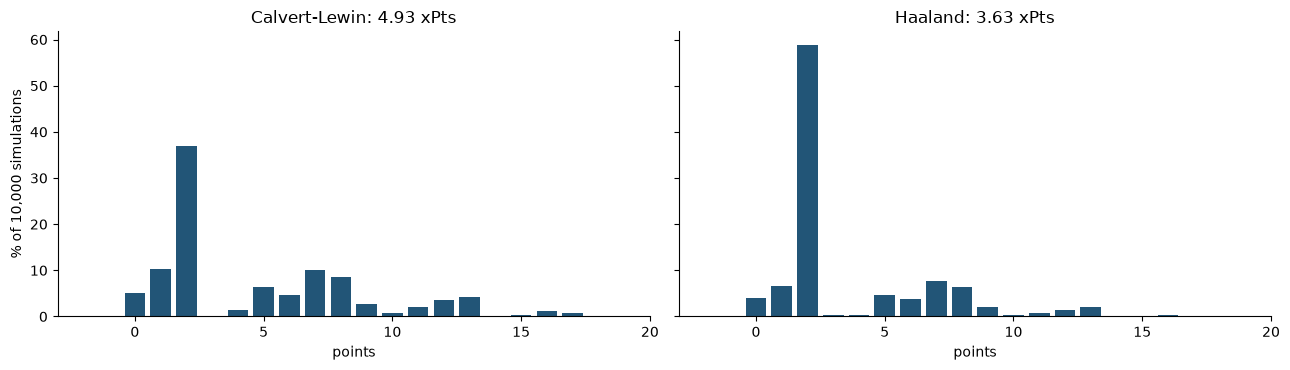

In [11]:
draws_model, test = det['model'], det['test']
pick = out.sort_values('gw_xpts', ascending=False).iloc[0]
rows = test.index[test.player_id.isin([pick.player_id, out.loc[out.name == 'Haaland', 'player_id'].iloc[0]])]
_, draws = draws_model.predict(test.loc[rows], minutes_probs=det['minutes_probs'].loc[rows],
                               extra_goal_rate=det['penalty'].loc[rows], return_draws=True)
fig, axes = plt.subplots(1, len(rows), figsize=(13, 3.8), sharey=True)
for ax, i, r in zip(np.atleast_1d(axes), range(len(rows)), rows):
    vals, counts = np.unique(draws[i], return_counts=True)
    ax.bar(vals, counts / counts.sum() * 100, color='#257')
    ax.set_title(f"{names[test.loc[r, 'player_id']]}: {draws[i].mean():.2f} xPts"); ax.set_xlabel('points'); ax.set_xlim(-3, 20)
np.atleast_1d(axes)[0].set_ylabel('% of 10,000 simulations'); plt.tight_layout(); plt.show()

That's the shape behind a single expected-points number: mostly 1–3 points, with a long tail of returns and hauls.
Two players with the same expected points can have very different tails, which is what P(haul) captures for captaincy.

### Captaincy shortlist
Captain points are doubled, so both the average **and** the upside matter:

In [12]:
cap = out.groupby(['player_id', 'name', 'team', 'position']).agg(xpts=('gw_xpts', 'first'), p_haul=('p_haul', 'first'),
                                                                p90=('p90', 'first'), fixtures=('fixture', ' + '.join)).reset_index()
cap.sort_values('xpts', ascending=False).head(10).drop(columns='player_id').round(2).reset_index(drop=True)

,name,team,position,xpts,p_haul,p90,fixtures
0,Calvert-Lewin,LEE,FWD,4.88,0.14,12.0,COV (H)
1,Muharemović,LEE,DEF,4.83,0.08,9.0,COV (H)
2,Justin,LEE,DEF,4.78,0.10,10.0,COV (H)
3,Elvedi,LEE,DEF,4.65,0.10,10.0,COV (H)
4,Richards,CRY,DEF,4.49,0.06,9.0,HUL (H)
5,Trafford,LEE,GKP,4.36,0.04,9.0,COV (H)
6,B.Fernandes,MUN,MID,4.30,0.11,10.0,BRE (H)
7,Gabriel,ARS,DEF,4.27,0.07,9.0,MCI (H)
8,E.Le Fée,SUN,MID,4.27,0.09,9.0,TOT (H)
9,Mukiele,SUN,DEF,4.17,0.07,9.0,TOT (H)


In [13]:
flag = out[(out.status != 'a') | (out.penalty_adjustment.abs() > 0.02)]
print('Players affected by the live overlays (injury flags / penalty duty):')
flag.sort_values('gw_xpts', ascending=False)[['name', 'team', 'status', 'chance', 'p_plays', 'penalty_adjustment', 'gw_xpts']].head(15).round(2).reset_index(drop=True)

Players affected by the live overlays (injury flags / penalty duty):


,name,team,status,chance,p_plays,penalty_adjustment,gw_xpts
0,Calvert-Lewin,LEE,a,100.0,0.95,-0.05,4.88
1,B.Fernandes,MUN,a,NaN,0.93,-0.03,4.30
2,E.Le Fée,SUN,a,NaN,0.96,-0.07,4.27
3,Groß,BHA,a,NaN,0.93,0.04,4.14
4,Gibbs-White,NFO,a,100.0,0.96,0.04,4.11
5,Szoboszlai,LIV,a,100.0,0.93,0.04,3.90
6,Tavernier,BOU,a,NaN,0.95,-0.03,3.89
7,Strand Larsen,CRY,a,100.0,0.92,-0.03,3.63
8,Palmer,CHE,a,100.0,0.94,-0.09,3.19
9,Gonzalo,FUL,a,NaN,0.87,0.09,2.72


---
## ✅ Decisions for you

1. **Adopt the component model (v1) as the production model**, stored by `python -m fpl_engine predict` and run by the
   daily job? *(It beats every baseline and the direct LightGBM on your primary metric, MAE and calibration.)*
2. **Team-specific home advantage**: keep off or turn on, based on section 4?
3. **What next?** Options:
   - **Notebook 09: recency weighting.** Your experiment: down-weight older seasons in training (half-life & season
     multipliers) and see if the top-20 metric improves.
   - **Cup & European minutes** (your follow-up from notebook 04).
   - **Multi-gameweek horizon** (3 / 5 / 10 GWs) for transfer planning.
   - **Improve haul probabilities** (P(haul) is slightly low).